<a href="https://colab.research.google.com/github/RamonMedina04/Sistemas-Inteligentes/blob/main/Tarea_Introducci%C3%B3n_a_visi%C3%B3n_computacional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bloque 1. Bibliotecas

Usamos TensorFlow/Keras para las redes, `tensorflow_datasets` para cargar el conjunto, NumPy para organizar los datos, `train_test_split` para obtener validación y Matplotlib para graficar. Son los mismos elementos usados en el notebook de MNIST, más el cargador `tfds` solicitado en la tarea.

In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [5]:
%pip install -q importlib_resources

## Bloque 2. Cargar Fashion-MNIST

Cada imagen mide **28 × 28 × 1** (un canal de escala de grises). La etiqueta es un entero del 0 al 9. El argumento `as_supervised=True` nos entrega pares `(imagen, etiqueta)`; `batch_size=32` agrupa los ejemplos para cargarlos.

In [6]:
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

nombres = [
    'Camiseta/top', 'Pantalon', 'Sueter', 'Vestido', 'Abrigo',
    'Sandalia', 'Camisa', 'Tenis', 'Bolsa', 'Botin'
]

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.PTHZ5Z_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.PTHZ5Z_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.


## Bloque 3. Convertir los lotes en arreglos NumPy

En el código de clase los datos `X_train` y `y_train` son arreglos. Aquí `tfds.load` devuelve lotes; los reunimos para poder usar `train_test_split` como se hizo en MNIST. **Las imágenes y sus etiquetas se recopilan juntas** para mantener la correspondencia.

In [7]:
def a_numpy(dataset):
    imagenes = []
    etiquetas = []
    for x, y in dataset:
        imagenes.append(x.numpy())
        etiquetas.append(y.numpy())
    return np.concatenate(imagenes), np.concatenate(etiquetas)

X_total, y_total = a_numpy(train_ds)
X_test, y_test = a_numpy(test_ds)

print('Entrenamiento original:', X_total.shape)
print('Prueba:', X_test.shape)

Entrenamiento original: (60000, 28, 28, 1)
Prueba: (10000, 28, 28, 1)


## Bloque 4. Mostrar imágenes

Con `imshow` comprobamos cómo son las entradas y qué etiqueta corresponde a cada imagen.

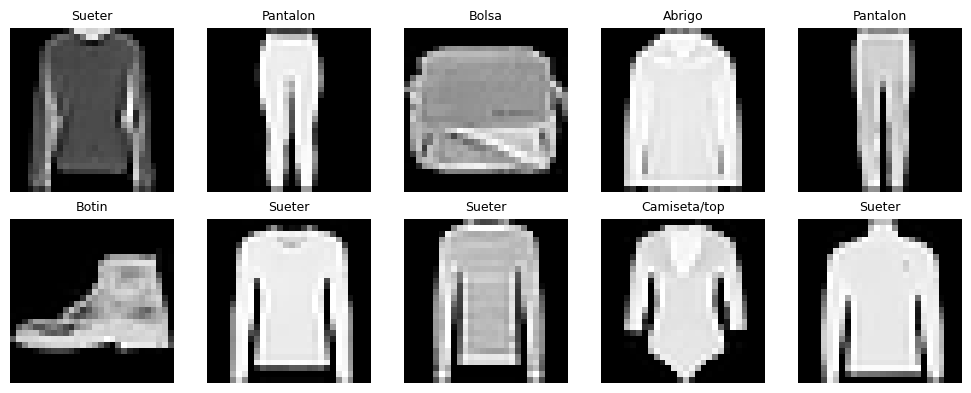

In [8]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_total[i, :, :, 0], cmap='gray')
    plt.title(nombres[y_total[i]], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Bloque 5. Separar validación y normalizar

Como en el notebook de MNIST, reservamos ejemplos para validación. Utilizamos el conjunto `test` original **solo al final**, después de escoger el modelo por accuracy de validación.

Dividir entre 255 transforma los píxeles de `[0,255]` a `[0,1]`. Los modelos reciben matrices con forma `(28,28,1)`, que después aplanará `Flatten`.

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X_total, y_total,
    test_size=0.10,
    random_state=42,
    stratify=y_total
)

X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print('Entrenamiento:', X_train.shape)
print('Validacion:', X_val.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (54000, 28, 28, 1)
Validacion: (6000, 28, 28, 1)
Prueba: (10000, 28, 28, 1)


## Bloque 6. Modelo 1: una capa oculta

`Flatten` transforma los **784 píxeles** en un vector. `Dense(128, relu)` aprende patrones no lineales. `Dense(10, softmax)` calcula probabilidades para las diez prendas.

Usamos `sparse_categorical_crossentropy` porque las etiquetas son números enteros del 0 al 9; `accuracy` mide la proporción de aciertos.

In [10]:
modelo1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

modelo1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Bloque 7. Modelo 2: dos capas ocultas

Es la misma arquitectura que el **primer modelo MNIST** visto en clase: `Flatten → 128 ReLU → 64 ReLU → 10 Softmax`. La diferencia es el conjunto de imágenes.

In [11]:
modelo2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

modelo2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Bloque 8. Modelo 3: representación 2D

Es una adaptación del **segundo modelo de MNIST** de tu profesor. La capa `Dense(2, activation='linear', name='rep_2d')` aprende **dos números por imagen** antes de clasificar. Estos dos números serán los ejes de la gráfica 2D.

Al comprimir la información a solo dos números, este modelo podría obtener menor accuracy que los otros; comparar eso también forma parte de la práctica.

In [12]:
modelo3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(2, activation='linear', name='rep_2d'),
    tf.keras.layers.Dense(10, activation='softmax')
])

modelo3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Bloque 9. Entrenar los tres modelos

`fit` ajusta los pesos usando propagación hacia adelante, pérdida, retropropagación y el optimizador Adam. `epochs=10` indica diez pasadas completas por los datos; `batch_size=32` indica el tamaño de los lotes. `validation_data` calcula accuracy sin actualizar los pesos con esos ejemplos.

In [13]:
historia1 = modelo1.fit(
    X_train, y_train, epochs=10, batch_size=32,
    validation_data=(X_val, y_val)
)

historia2 = modelo2.fit(
    X_train, y_train, epochs=10, batch_size=32,
    validation_data=(X_val, y_val)
)

historia3 = modelo3.fit(
    X_train, y_train, epochs=10, batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8216 - loss: 0.5081 - val_accuracy: 0.8495 - val_loss: 0.4013
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8637 - loss: 0.3833 - val_accuracy: 0.8610 - val_loss: 0.3746
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8755 - loss: 0.3436 - val_accuracy: 0.8628 - val_loss: 0.3927
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8829 - loss: 0.3177 - val_accuracy: 0.8847 - val_loss: 0.3143
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8904 - loss: 0.2984 - val_accuracy: 0.8785 - val_loss: 0.3263
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8951 - loss: 0.2820 - val_accuracy: 0.8805 - val_loss: 0.3091
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9006 - loss: 0.2708 - val_accuracy: 0.8818 - val_loss: 0.3298
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9033 - loss: 0.2607 -

## Bloque 10. Comparar `accuracy` de validación

`evaluate` devuelve pérdida y métricas. La **accuracy** es el porcentaje de imágenes clasificadas correctamente. Elegimos el mejor modelo comparando únicamente el conjunto de **validación**, no el de prueba.

Modelo 1: accuracy de validacion = 88.85%
Modelo 2: accuracy de validacion = 88.75%
Modelo 3 (2D): accuracy de validacion = 85.93%


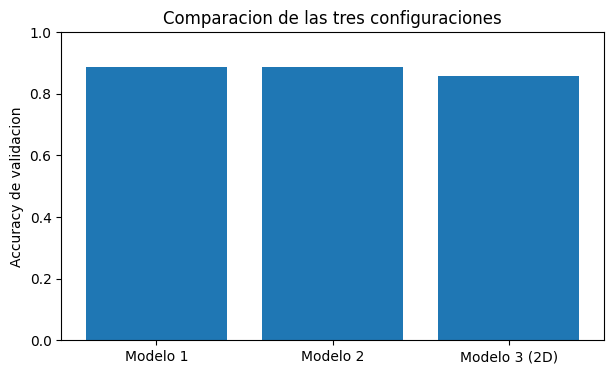

In [14]:
_, acc1 = modelo1.evaluate(X_val, y_val, verbose=0)
_, acc2 = modelo2.evaluate(X_val, y_val, verbose=0)
_, acc3 = modelo3.evaluate(X_val, y_val, verbose=0)

nombres_modelos = ['Modelo 1', 'Modelo 2', 'Modelo 3 (2D)']
accuracies = [acc1, acc2, acc3]

for nombre, acc in zip(nombres_modelos, accuracies):
    print(f'{nombre}: accuracy de validacion = {acc:.2%}')

plt.figure(figsize=(7, 4))
plt.bar(nombres_modelos, accuracies)
plt.ylim(0, 1)
plt.ylabel('Accuracy de validacion')
plt.title('Comparacion de las tres configuraciones')
plt.show()

## Bloque 11. Curvas de accuracy

Igual que en `plot_learning_curve` del notebook original, graficamos la accuracy de validación después de cada época para observar cómo evoluciona el aprendizaje.

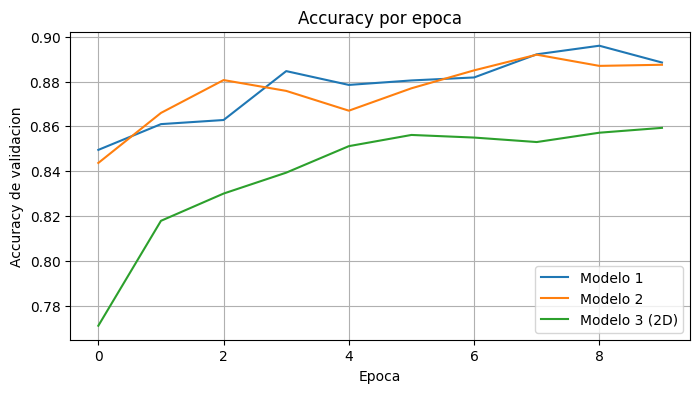

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(historia1.history['val_accuracy'], label='Modelo 1')
plt.plot(historia2.history['val_accuracy'], label='Modelo 2')
plt.plot(historia3.history['val_accuracy'], label='Modelo 3 (2D)')
plt.xlabel('Epoca')
plt.ylabel('Accuracy de validacion')
plt.title('Accuracy por epoca')
plt.legend()
plt.grid(True)
plt.show()

## Bloque 12. Graficar la representación en 2D (requisito de la tarea)

Igual que en el segundo modelo de MNIST, extraemos la salida de la capa llamada `rep_2d`. Para cada imagen, esa capa genera dos coordenadas. Con `scatter` dibujamos un punto por imagen, coloreado según su clase real.

Esta **no es PCA**: las coordenadas son representaciones aprendidas por la propia red durante el entrenamiento supervisado.

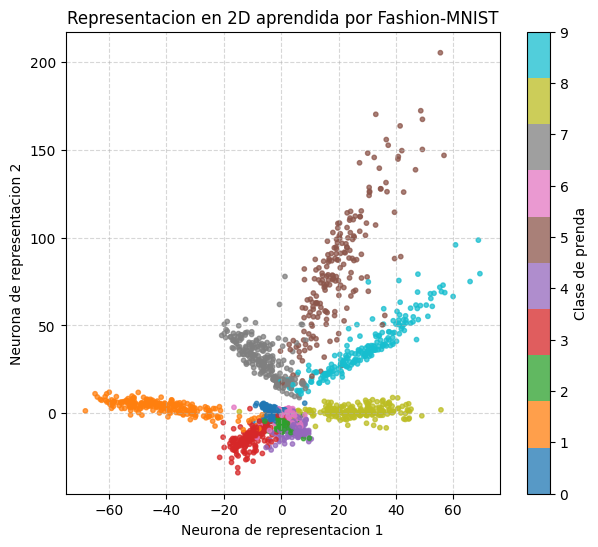

In [16]:
extractor = tf.keras.Model(
    inputs=modelo3.inputs,
    outputs=modelo3.get_layer('rep_2d').output
)

n = 2000
puntos2d = extractor.predict(X_val[:n], verbose=0)

plt.figure(figsize=(7, 6))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_val[:n],
    cmap='tab10',
    s=10,
    alpha=0.75
)
plt.title('Representacion en 2D aprendida por Fashion-MNIST')
plt.xlabel('Neurona de representacion 1')
plt.ylabel('Neurona de representacion 2')
plt.colorbar(scatter_plot, ticks=range(10), label='Clase de prenda')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Bloque 13. Evaluación final con prueba

Escogemos el modelo con **mayor accuracy de validación** y únicamente entonces calculamos su accuracy en los ejemplos de prueba. Así evitamos elegir un modelo en función de sus resultados de prueba.

In [17]:
modelos = [modelo1, modelo2, modelo3]
mejor_indice = np.argmax(accuracies)
mejor_modelo = modelos[mejor_indice]

perdida_test, accuracy_test = mejor_modelo.evaluate(X_test, y_test, verbose=0)

print('Mejor configuracion:', nombres_modelos[mejor_indice])
print(f'Accuracy final de prueba: {accuracy_test:.2%}')

Mejor configuracion: Modelo 1
Accuracy final de prueba: 88.65%


## Bloque 14. Predicciones de ejemplo

`predict` devuelve diez probabilidades para cada imagen. `argmax` encuentra la clase con mayor probabilidad. Comparamos la etiqueta real con la predicción de la red.

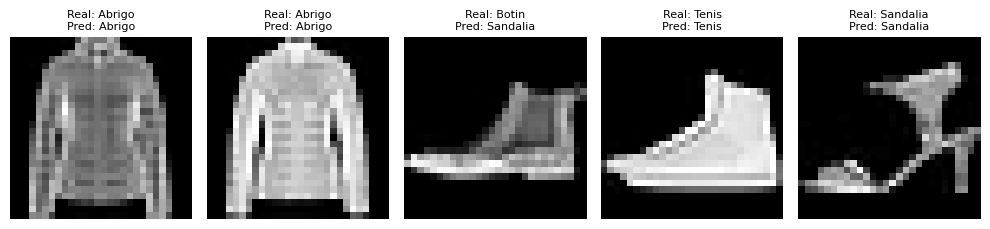

In [18]:
probabilidades = mejor_modelo.predict(X_test[:5], verbose=0)
predicciones = np.argmax(probabilidades, axis=1)

plt.figure(figsize=(10, 2.5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i, :, :, 0], cmap='gray')
    plt.title(f'Real: {nombres[y_test[i]]}\nPred: {nombres[predicciones[i]]}', fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()